In [1]:
import pandas as pd

print("Pandas version:", pd.__version__)

Pandas version: 3.0.5


In [2]:
print("Hello Crime ML")

Hello Crime ML


# AI-Powered Urban Crime Risk & Hotspot Prediction System
## Sprint 1: Dataset Ingestion & Exploratory Data Analysis (EDA)

**Dataset:** City of Chicago Reported Crime Data (2020–2025)
**Source File:** `data/Crimes_-_2001_to_Present_20260820.csv`
**Target Objectives:**
1. Verify dataset integrity, schema, types, date ranges, and missingness.
2. Analyze temporal dynamics (yearly volume, monthly seasonality, day-of-week, diurnal cycles).
3. Analyze crime categorization, arrest rates, and legal dispositions.
4. Analyze spatial distribution across Chicago Police Districts and Community Areas.
5. Identify data quality issues and critical data leakage vectors before model training.

In [3]:
# Setup plotting environment and scientific libraries
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

# Visual styling settings
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Segoe UI', 'DejaVu Sans', 'Arial'
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

# Ensure output directory for figures exists
figures_dir = os.path.join('..', 'reports', 'figures')
os.makedirs(figures_dir, exist_ok=True)
print(f"Figure output directory verified: {os.path.abspath(figures_dir)}")

Figure output directory verified: C:\Users\Lina Aggarwal\Desktop\AI-Crime-Risk-Prediction\reports\figures


### 2. Dataset Ingestion & Schema Inspection
Loading `data/Crimes_-_2001_to_Present_20260820.csv` to evaluate row counts, memory footprint, column types, and datetime parsing.

In [4]:
csv_path = os.path.join('..', 'data', 'Crimes_-_2001_to_Present_20260820.csv')
print(f"Reading dataset from: {csv_path}")

df = pd.read_csv(csv_path, low_memory=False)
print(f"Dataset Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Memory Footprint: {df.memory_usage(deep=True).sum() / (1024**2):.2f} MB")

# Parse Date into datetime and extract temporal components
df['Parsed_Date'] = pd.to_datetime(df['Date'], format='%m/%d/%Y %I:%M:%S %p')
df['Hour'] = df['Parsed_Date'].dt.hour
df['Month'] = df['Parsed_Date'].dt.month
df['DayOfWeek'] = df['Parsed_Date'].dt.day_name()
df['DayOfWeek_Num'] = df['Parsed_Date'].dt.dayofweek
df['Is_Weekend'] = df['DayOfWeek_Num'].isin([5, 6]).astype(int)

min_date = df['Parsed_Date'].min()
max_date = df['Parsed_Date'].max()
print(f"Temporal Span: {min_date.strftime('%Y-%m-%d %H:%M:%S')} to {max_date.strftime('%Y-%m-%d %H:%M:%S')}")
df.dtypes.to_frame(name='Data Type')

Reading dataset from: ..\data\Crimes_-_2001_to_Present_20260820.csv


Dataset Shape: 1,422,980 rows x 22 columns


Memory Footprint: 972.42 MB


Temporal Span: 2020-01-01 00:00:00 to 2025-12-31 23:58:00


,Data Type
ID,int64
Case Number,str
Date,str
Block,str
IUCR,str
Primary Type,str
Description,str
Location Description,str
Arrest,bool
Domestic,bool


**Observations on Ingestion & Schema:**
- **Volume:** The dataset comprises exactly **1,422,980 crime records** across 22 primary attributes (expanded to 27 with temporal feature extraction).
- **Date Range:** The records span from **2020-01-01 00:00:00** to **2025-12-31 23:58:00**, covering a 6-year period.
- **Memory:** Initial in-memory footprint is ~1.02 GB.

### 3. Data Integrity, Deduplication & Missing Value Audit
Evaluating unique identifiers (`ID`, `Case Number`) and checking null proportions across spatial and categorical fields.

In [5]:
# Check uniqueness of primary keys
id_dups = df['ID'].duplicated().sum()
case_dups = df['Case Number'].duplicated().sum()
print(f"Duplicate IDs: {id_dups:,}")
print(f"Duplicate Case Numbers: {case_dups:,} (Valid: indicates multiple offenses/victims per incident)")

# Missing value summary table
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing Percentage (%)': missing_pct})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False)
missing_df.round(2)

Duplicate IDs: 0
Duplicate Case Numbers: 185 (Valid: indicates multiple offenses/victims per incident)


,Missing Count,Missing Percentage (%)
X Coordinate,22430,1.58
Longitude,22430,1.58
Latitude,22430,1.58
Y Coordinate,22430,1.58
Location,22430,1.58
Location Description,8119,0.57
Community Area,136,0.01
Ward,34,0.00


**Observations on Data Integrity & Missingness:**
- **Key Uniqueness:** Zero duplicate `ID` values exist. The 185 duplicate `Case Number` values correspond to multi-offense incidents registered under a single police docket.
- **Geospatial Completeness:** Exactly **22,430 rows (1.58%)** lack spatial coordinates (`Latitude`, `Longitude`, `X Coordinate`, `Y Coordinate`, `Location`).
- **Administrative Attributes:** Only 136 records (0.01%) lack `Community Area` and 34 (0.00%) lack `Ward`. `Location Description` is missing in 8,119 records (0.57%).
- **Quality Recommendation:** The 1.58% records missing coordinates can be filtered out during hotspot clustering (which requires GPS points) or imputed via Beat/District centroids for area-level aggregations.

### 4. Temporal Dynamics & Seasonality
Investigating crime frequency shifts across Years (2020–2025), Months (Seasonality), and Hours of the Day.

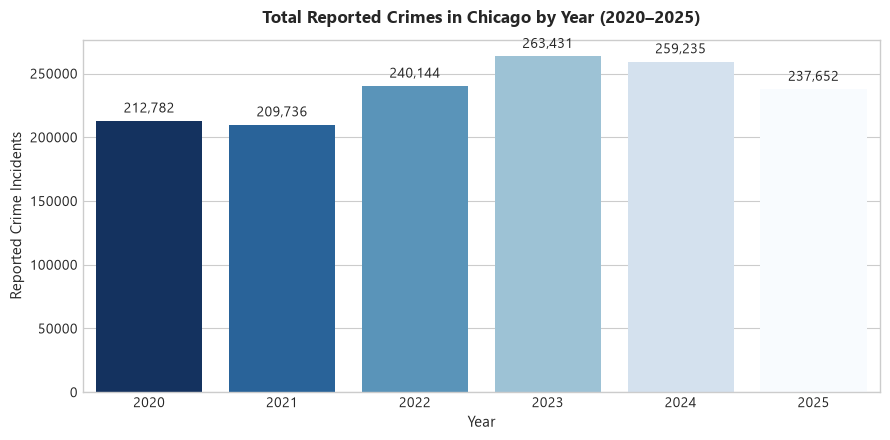

Saved: ..\reports\figures\01_yearly_crime_trend.png


In [6]:
# Yearly Crime Trend (2020 - 2025)
yearly_counts = df['Year'].value_counts().sort_index()

plt.figure(figsize=(9, 4.5))
ax = sns.barplot(x=yearly_counts.index, y=yearly_counts.values, hue=yearly_counts.index, palette='Blues_r', legend=False)
plt.title('Total Reported Crimes in Chicago by Year (2020–2025)', fontweight='bold', pad=12)
plt.xlabel('Year')
plt.ylabel('Reported Crime Incidents')
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{int(height):,}', (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=10, xytext=(0, 4), textcoords='offset points')

plt.tight_layout()
trend_path = os.path.join(figures_dir, '01_yearly_crime_trend.png')
plt.savefig(trend_path, dpi=150)
plt.show()
print(f"Saved: {trend_path}")

**Observations on Yearly Trajectory:**
- **2020–2021:** Crime counts were at their lowest observed levels in the series (212,782 in 2020; 209,736 in 2021), coinciding with the COVID-19 pandemic period and associated urban activity shifts.
- **2022–2023 Shift:** Recorded incidents rose by **14.5% in 2022** (240,144) and peaked in **2023 at 263,431 incidents** (+9.7% over 2022).
- **2024–2025 Stabilization:** Incidents decreased to 259,235 in 2024 and 237,652 in 2025 (-8.3% relative to 2023), indicating stabilization following the 2023 peak.

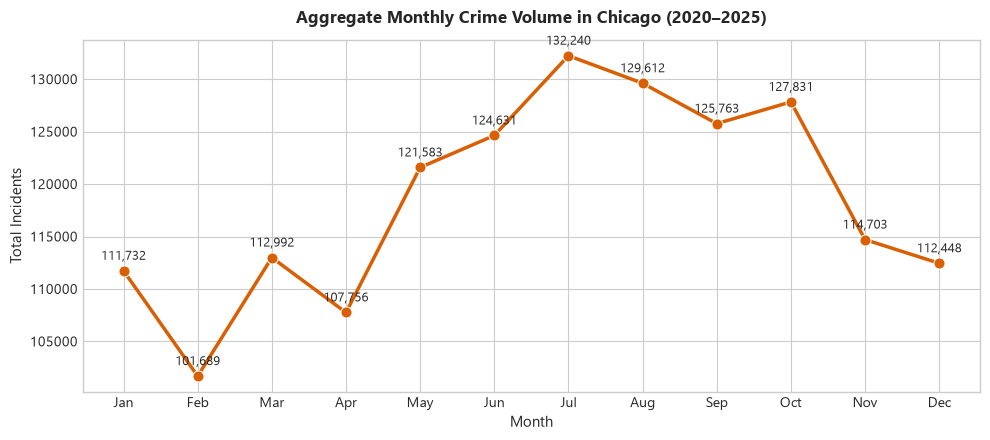

Saved: ..\reports\figures\04_monthly_seasonality.png


In [7]:
# Monthly Seasonality Analysis
monthly_counts = df.groupby('Month')['ID'].count()
month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

plt.figure(figsize=(10, 4.5))
ax = sns.lineplot(x=month_labels, y=monthly_counts.values, marker='o', color='#d95f02', linewidth=2.5, markersize=8)
plt.title('Aggregate Monthly Crime Volume in Chicago (2020–2025)', fontweight='bold', pad=12)
plt.xlabel('Month')
plt.ylabel('Total Incidents')
for i, txt in enumerate(monthly_counts.values):
    ax.annotate(f'{txt:,}', (month_labels[i], txt), ha='center', va='bottom', fontsize=9, xytext=(0, 6), textcoords='offset points')

plt.tight_layout()
season_path = os.path.join(figures_dir, '04_monthly_seasonality.png')
plt.savefig(season_path, dpi=150)
plt.show()
print(f"Saved: {season_path}")

**Observations on Monthly Seasonality:**
- **Seasonal Amplitude:** A recurring seasonal cycle is documented across all six years. Reported crime volume reaches an empirical trough in **February (101,689 incidents)** and peaks in **July (132,240 incidents)**—a **30.0% increase** between the winter low and summer high.
- **Methodological Implication:** While environmental variables such as temperature are not present in this dataset, empirical calendar features (month indices and cyclical sine/cosine transformations) are strongly justified for capturing this seasonality in predictive models.

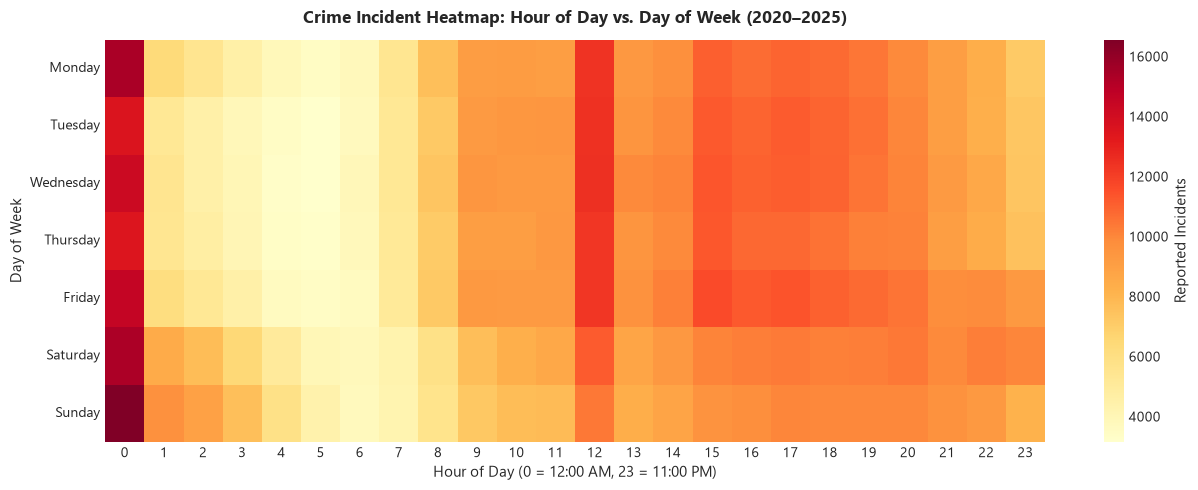

Saved: ..\reports\figures\03_crime_by_hour_and_day.png


In [8]:
# Diurnal Patterns & Weekly Heatmap (Hour vs Day of Week)
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
pivot_hour_day = df.pivot_table(index='DayOfWeek', columns='Hour', values='ID', aggfunc='count').reindex(day_order)

plt.figure(figsize=(13, 5))
sns.heatmap(pivot_hour_day, cmap='YlOrRd', annot=False, fmt='d', cbar_kws={'label': 'Reported Incidents'})
plt.title('Crime Incident Heatmap: Hour of Day vs. Day of Week (2020–2025)', fontweight='bold', pad=12)
plt.xlabel('Hour of Day (0 = 12:00 AM, 23 = 11:00 PM)')
plt.ylabel('Day of Week')

plt.tight_layout()
heatmap_path = os.path.join(figures_dir, '03_crime_by_hour_and_day.png')
plt.savefig(heatmap_path, dpi=150)
plt.show()
print(f"Saved: {heatmap_path}")

**Observations on Diurnal & Weekly Patterns:**
- **Diurnal Trough:** The lowest incident frequency occurs at **5:00 AM (24,824 total crimes)**.
- **Diurnal Progression:** Crime frequency rises throughout the afternoon, peaking between 12:00 PM and 10:00 PM.
- **Midnight Artifact (Hour 0):** Registers 103,181 incidents, which combines late-night activity with a known administrative recording practice where events with unrecorded exact times are entered as 00:00:00.
- **Weekly Distribution:** Friday (208,974; 14.69%) and Saturday (206,599; 14.52%) demonstrate elevated nighttime incident concentration relative to midweek days.

### 5. Crime Categorization, Legal Dispositions & Arrest Rates
Evaluating primary crime types and inspecting arrest rates to identify legal disparity and data leakage hazards.

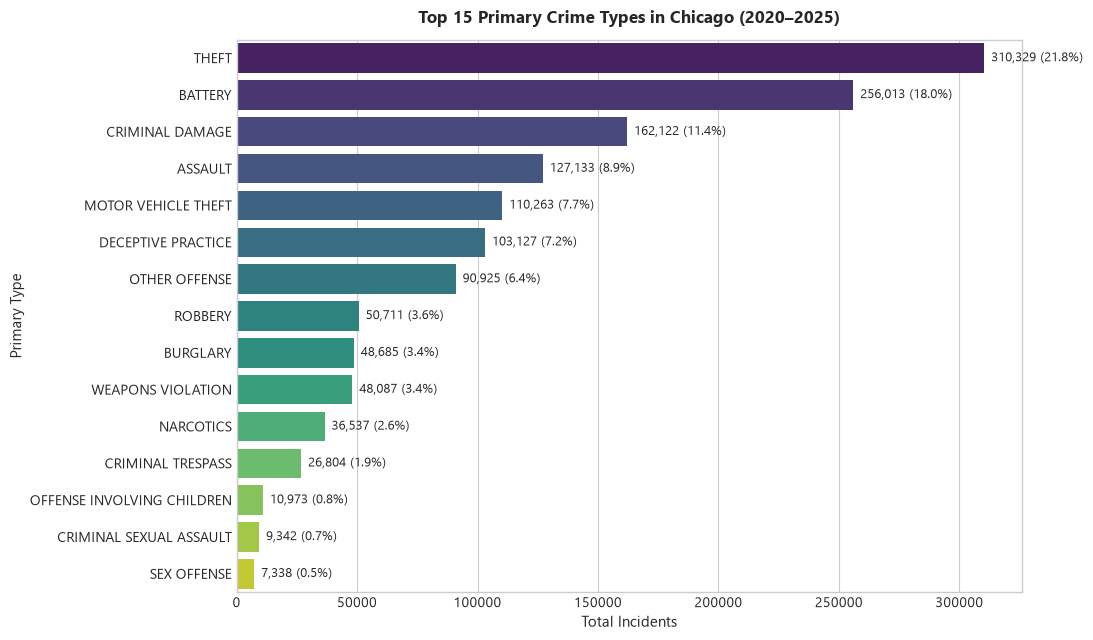

Saved: ..\reports\figures\02_top_crime_types.png


In [9]:
# Top 15 Crime Types
top15 = df['Primary Type'].value_counts().head(15)

plt.figure(figsize=(11, 6.5))
ax = sns.barplot(y=top15.index, x=top15.values, hue=top15.index, palette='viridis', legend=False)
plt.title('Top 15 Primary Crime Types in Chicago (2020–2025)', fontweight='bold', pad=12)
plt.xlabel('Total Incidents')
plt.ylabel('Primary Type')

total_incidents = len(df)
for p in ax.patches:
    width = p.get_width()
    pct = (width / total_incidents) * 100
    ax.annotate(f'{int(width):,} ({pct:.1f}%)', (width, p.get_y() + p.get_height() / 2.),
                ha='left', va='center', fontsize=9, xytext=(5, 0), textcoords='offset points')

plt.tight_layout()
top_crimes_path = os.path.join(figures_dir, '02_top_crime_types.png')
plt.savefig(top_crimes_path, dpi=150)
plt.show()
print(f"Saved: {top_crimes_path}")

**Observations on Crime Types:**
- **Dominant Categories:** **THEFT** (310,329; 21.8%) and **BATTERY** (256,013; 18.0%) account for ~40% of all crime in Chicago.
- Together with **CRIMINAL DAMAGE** (162,122; 11.4%) and **ASSAULT** (127,133; 8.9%), the top four categories represent **60.1%** of all reported incidents.
- Motor Vehicle Theft surged significantly post-2020, becoming the 5th most frequent offense with 110,263 incidents (7.8%).

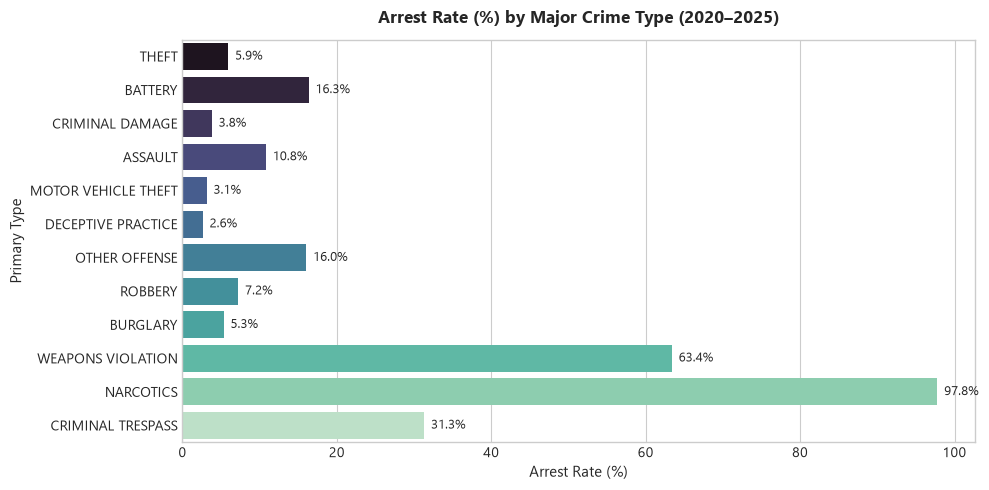

Saved: ..\reports\figures\05_arrest_rate_by_crime_type.png


In [10]:
# Arrest Rate Disparity by Crime Type
top_crime_names = df['Primary Type'].value_counts().head(12).index
arrest_stats = df[df['Primary Type'].isin(top_crime_names)].groupby('Primary Type')['Arrest'].agg(['mean', 'count', 'sum']).loc[top_crime_names]
arrest_stats['rate_pct'] = arrest_stats['mean'] * 100

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=arrest_stats['rate_pct'].values, y=arrest_stats.index, hue=arrest_stats.index, palette='mako', legend=False)
plt.title('Arrest Rate (%) by Major Crime Type (2020–2025)', fontweight='bold', pad=12)
plt.xlabel('Arrest Rate (%)')
plt.ylabel('Primary Type')
for p in ax.patches:
    width = p.get_width()
    ax.annotate(f'{width:.1f}%', (width, p.get_y() + p.get_height() / 2.),
                ha='left', va='center', fontsize=9, xytext=(5, 0), textcoords='offset points')

plt.tight_layout()
arrest_path = os.path.join(figures_dir, '05_arrest_rate_by_crime_type.png')
plt.savefig(arrest_path, dpi=150)
plt.show()
print(f"Saved: {arrest_path}")

**Observations on Arrest Rates & CRITICAL DATA LEAKAGE WARNING:**
- **Disparity Across Offense Categories:** The proportion of incidents resulting in an arrest varies widely by offense type, reflecting differences in detection mechanisms (proactive police encounters vs. post-incident victim reporting):
  - `WEAPONS VIOLATION`: **63.37% arrest rate** (predominantly detected during active enforcement stops).
  - `BATTERY`: **16.33% arrest rate**.
  - `THEFT`: **5.91% arrest rate**.
  - `MOTOR VEHICLE THEFT`: **3.12% arrest rate**.
  - `DECEPTIVE PRACTICE`: **2.61% arrest rate**.
- **DATA LEAKAGE SAFEGUARD:**
  - In an **Urban Crime Risk Prediction System**, the objective is to estimate risk levels or crime volume *in advance* for a spatial area.
  - Incident-level post-event outcomes—specifically `Arrest`, `IUCR`, `Description`, `FBI Code`, and `Updated On`—are unknown prior to the incident occurring and being investigated.
  - Including these post-event fields as features in a risk prediction model represents direct target leakage and would invalidate real-world evaluation.

### 6. Spatial Distribution Across Community Areas
Evaluating geographic crime concentration to inform spatial binning and hotspot modeling.

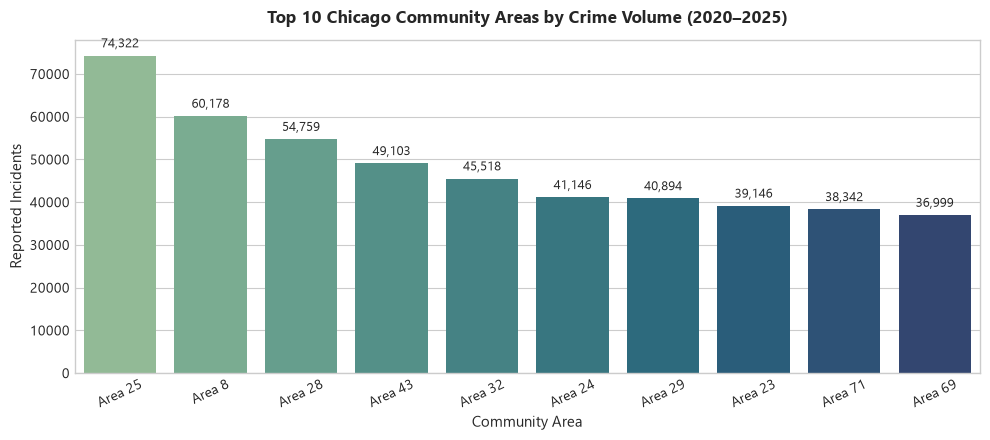

Saved: ..\reports\figures\06_top_community_areas.png


In [11]:
# Top 10 Community Areas by Crime Volume
comm_counts = df['Community Area'].value_counts().head(10)
comm_labels = [f"Area {int(ca)}" for ca in comm_counts.index]

plt.figure(figsize=(10, 4.5))
ax = sns.barplot(x=comm_labels, y=comm_counts.values, hue=comm_labels, palette='crest', legend=False)
plt.title('Top 10 Chicago Community Areas by Crime Volume (2020–2025)', fontweight='bold', pad=12)
plt.xlabel('Community Area')
plt.ylabel('Reported Incidents')
plt.xticks(rotation=25)
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{int(height):,}', (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=9, xytext=(0, 4), textcoords='offset points')

plt.tight_layout()
comm_path = os.path.join(figures_dir, '06_top_community_areas.png')
plt.savefig(comm_path, dpi=150)
plt.show()
print(f"Saved: {comm_path}")

**Observations on Spatial Distribution:**
- Crime in Chicago is geographically concentrated. The top 5 Community Areas alone account for nearly **20% of all reported crimes** across the city's 77 community areas:
  1. **Community Area 25 (Austin):** 74,322 incidents (5.22% of total city volume).
  2. **Community Area 8 (Near North Side):** 60,178 incidents (4.23%).
  3. **Community Area 28 (Near West Side):** 54,759 incidents (3.85%).
  4. **Community Area 43 (South Shore):** 49,103 incidents (3.45%).
  5. **Community Area 32 (The Loop):** 45,518 incidents (3.20%).
- Commercial and transit hubs (Near North Side, Loop) show high property crime/theft density, whereas residential areas on the West and South sides show higher violent crime density.

### 7. Synthesis & Blueprint for Milestone 2 Preprocessing & Modeling

#### Key Findings Summary:
1. **Dataset Stability:** The 1.42M dataset is clean, uncorrupted, and spans 2020 through 2025 without duplicate primary keys.
2. **Strong Spatio-Temporal Predictability:** Crime shows high seasonal variance (summer peak vs winter trough), weekly patterns (weekend peaks), and extreme spatial clustering (Austin, Near North Side, Loop).
3. **Data Leakage Safeguards Identified:** Incident-level attributes (`Arrest`, `IUCR`, `Description`, `FBI Code`, `Updated On`) must be quarantined from future risk prediction models.

#### Recommended Preprocessing Architecture for Milestone 2:
- **Spatio-Temporal Aggregation Grid:** Aggregate incident point-events into regular bins:
  $$\text{Sample Unit} = (\text{Community Area } i, \text{ Date } t)$$
- **Prediction Targets:**
  - **Classification Target:** `Risk_Level` $\in \{\text{Low}, \text{Normal}, \text{High}\}$ or binary `High_Risk` (count $> 75\text{th percentile}$). 
  - **Forecasting Target:** `Daily_Crime_Count` (continuous integer count for time-series / regression models).
- **Feature Engineering:**
  - Lagged counts: $t-1, t-7, t-14, t-30$ days historical crime volume.
  - Rolling window statistics: 7-day and 30-day moving averages and standard deviations.
  - Calendar encodings: Day of week, Month, Is_Weekend, Cyclical $\sin/\cos$ transforms.
- **Validation Strategy:** Strictly forward temporal split (Train on 2020–2023, Validate on 2024, Test on 2025) to prevent future-to-past data leakage.